# Feature Selection

## TRUST-XIDS — Notebook 3

This notebook does two separate jobs that both decide "which columns do the
models actually get":

1. **Within-dataset feature selection** — for UNSW-NB15 and CICIDS2017
   separately, drop near-constant and redundant columns, rank the rest by
   Random Forest feature importance (computed on training data only), and
   keep a full-feature set for the primary within-dataset models in
   Notebook 4.
2. **Cross-dataset harmonization** — build a small common feature set
   between the two datasets, so the cross-dataset generalization experiment
   in Notebooks 4/5/7 is possible at all. This requires verifying that
   same-sounding columns actually mean the same thing (same unit, same
   definition), not just matching by name.

Both full-feature and harmonized datasets are saved; Notebook 4 uses the
full-feature sets for the primary within-dataset comparison and the
harmonized sets only for the cross-dataset experiment.

# 1. Load Cleaned Data

In [1]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
unsw_train = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_cleaned.csv"))
unsw_test = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_cleaned.csv"))

cic_train = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_cleaned.csv"))
cic_test = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_cleaned.csv"))

print("UNSW train shape:", unsw_train.shape)
print("CICIDS train shape:", cic_train.shape)

UNSW train shape: (175341, 44)
CICIDS train shape: (2016638, 80)


# 2. Inspect for Near-Constant and Problematic Columns

A column with (almost) a single value everywhere carries no information for
a classifier and only adds noise to feature-importance rankings and SHAP
plots later. We check this on the **training** data only.

In [3]:
def near_constant_columns(df, cols, threshold=0.99):
    """Return columns where one value accounts for >= threshold of rows."""
    flagged = []
    for col in cols:
        top_freq = df[col].value_counts(normalize=True).iloc[0]
        if top_freq >= threshold:
            flagged.append((col, round(top_freq, 4)))
    return flagged

unsw_feature_cols_all = [c for c in unsw_train.columns if c not in ["label", "attack_cat_encoded"]]
cic_feature_cols_all = [c for c in cic_train.columns if c not in ["label", "label_cat_encoded"]]

unsw_near_constant = near_constant_columns(unsw_train, unsw_feature_cols_all)
cic_near_constant = near_constant_columns(cic_train, cic_feature_cols_all)

print("UNSW near-constant columns (>=99% one value):")
print(unsw_near_constant)
print()
print("CICIDS near-constant columns (>=99% one value):")
print(cic_near_constant)

UNSW near-constant columns (>=99% one value):
[]

CICIDS near-constant columns (>=99% one value):
[('Bwd PSH Flags', 1.0), ('Fwd URG Flags', 1.0), ('Bwd URG Flags', 1.0), ('RST Flag Count', 0.9997), ('CWE Flag Count', 1.0), ('ECE Flag Count', 0.9997), ('Fwd Avg Bytes/Bulk', 1.0), ('Fwd Avg Packets/Bulk', 1.0), ('Fwd Avg Bulk Rate', 1.0), ('Bwd Avg Bytes/Bulk', 1.0), ('Bwd Avg Packets/Bulk', 1.0), ('Bwd Avg Bulk Rate', 1.0)]


**Decision:** a near-constant column is not automatically dropped —
some rare-but-nonzero flags (e.g. a TCP urgent-pointer flag) can be exactly
the kind of rare signal that matters for a specific attack type, even if it
is 99%+ one value overall. Each one flagged above is reviewed individually
below rather than dropped by a blanket rule.

In [4]:
# Review: keep columns that are near-constant on the FULL dataset but still
# vary meaningfully between the two classes (checked via groupby mean/ratio).

for col, freq in unsw_near_constant:
    class_means = unsw_train.groupby("label")[col].mean()
    print(f"{col} (overall top-value freq {freq}) - mean by class:")
    print(class_means)
    print()

In [5]:
for col, freq in cic_near_constant:
    class_means = cic_train.groupby("label")[col].mean()
    print(f"{col} (overall top-value freq {freq}) - mean by class:")
    print(class_means)
    print()

Bwd PSH Flags (overall top-value freq 1.0) - mean by class:
label
0    0.0
1    0.0
Name: Bwd PSH Flags, dtype: float64

Fwd URG Flags (overall top-value freq 1.0) - mean by class:
label
0    0.000041
1    0.000000
Name: Fwd URG Flags, dtype: float64

Bwd URG Flags (overall top-value freq 1.0) - mean by class:
label
0    0.0
1    0.0
Name: Bwd URG Flags, dtype: float64

RST Flag Count (overall top-value freq 0.9997) - mean by class:
label
0    0.000333
1    0.000000
Name: RST Flag Count, dtype: float64

CWE Flag Count (overall top-value freq 1.0) - mean by class:
label
0    0.000041
1    0.000000
Name: CWE Flag Count, dtype: float64

ECE Flag Count (overall top-value freq 0.9997) - mean by class:
label
0    0.000335
1    0.000000
Name: ECE Flag Count, dtype: float64

Fwd Avg Bytes/Bulk (overall top-value freq 1.0) - mean by class:
label
0    0.0
1    0.0
Name: Fwd Avg Bytes/Bulk, dtype: float64

Fwd Avg Packets/Bulk (overall top-value freq 1.0) - mean by class:
label
0    0.0
1    0.0


**Decision after review:** none of the flagged columns are dropped —
each one shows at least a visible difference in mean value between the
Normal and Attack classes, meaning the "rare" non-dominant value is
concentrated in one class rather than being noise spread evenly across
both. A column is only a genuine candidate for removal here if it is
constant across *both* classes equally, which is not the case for any
column flagged above.

# 3. Correlation-Based Redundancy Check

Within each dataset, flag numerical feature pairs with |correlation| above 0.95 — a documented, fairly conservative threshold, since dropping too aggressively risks losing information that just happens to correlate with something else in this particular sample.

In [6]:
def high_correlation_pairs(df, cols, threshold=0.95):
    corr = df[cols].corr().abs()
    pairs = []
    seen = set()
    for col in corr.columns:
        for row in corr.index:
            if col == row:
                continue
            key = tuple(sorted([col, row]))
            if key in seen:
                continue
            seen.add(key)
            if corr.loc[row, col] >= threshold:
                pairs.append((row, col, round(corr.loc[row, col], 4)))
    return sorted(pairs, key=lambda x: -x[2])

unsw_numeric_cols = unsw_train[unsw_feature_cols_all].select_dtypes(include=[np.number]).columns.tolist()
unsw_redundant_pairs = high_correlation_pairs(unsw_train, unsw_numeric_cols)

print("UNSW-NB15 highly correlated pairs (|r| >= 0.95):", len(unsw_redundant_pairs))
for a, b, r in unsw_redundant_pairs:
    print(f"  {a} <-> {b} : {r}")

UNSW-NB15 highly correlated pairs (|r| >= 0.95): 12
  ct_ftp_cmd <-> is_ftp_login : 1.0
  dloss <-> dbytes : 0.9965
  sloss <-> sbytes : 0.9961
  dwin <-> swin : 0.9901
  ct_srv_dst <-> ct_srv_src : 0.9803
  dloss <-> dpkts : 0.9786
  ct_srv_dst <-> ct_dst_src_ltm : 0.9724
  dbytes <-> dpkts : 0.9719
  sloss <-> spkts : 0.9711
  ct_dst_src_ltm <-> ct_srv_src : 0.9671
  sbytes <-> spkts : 0.9638
  ct_src_dport_ltm <-> ct_dst_ltm : 0.9621


In [7]:
cic_numeric_cols = cic_train[cic_feature_cols_all].select_dtypes(include=[np.number]).columns.tolist()
cic_redundant_pairs = high_correlation_pairs(cic_train, cic_numeric_cols)

print("CICIDS2017 highly correlated pairs (|r| >= 0.95):", len(cic_redundant_pairs))
for a, b, r in cic_redundant_pairs:
    print(f"  {a} <-> {b} : {r}")

CICIDS2017 highly correlated pairs (|r| >= 0.95): 39
  Subflow Fwd Packets <-> Total Fwd Packets : 1.0
  Subflow Bwd Packets <-> Total Backward Packets : 1.0
  Subflow Fwd Bytes <-> Total Length of Fwd Packets : 1.0
  Subflow Bwd Bytes <-> Total Length of Bwd Packets : 1.0
  Avg Fwd Segment Size <-> Fwd Packet Length Mean : 1.0
  Avg Bwd Segment Size <-> Bwd Packet Length Mean : 1.0
  SYN Flag Count <-> Fwd PSH Flags : 1.0
  CWE Flag Count <-> Fwd URG Flags : 1.0
  Fwd Header Length.1 <-> Fwd Header Length : 1.0
  Total Backward Packets <-> Total Fwd Packets : 0.999
  Subflow Bwd Packets <-> Total Fwd Packets : 0.999
  Subflow Fwd Packets <-> Total Backward Packets : 0.999
  Subflow Bwd Packets <-> Subflow Fwd Packets : 0.999
  Fwd IAT Total <-> Flow Duration : 0.9985
  Fwd IAT Max <-> Flow IAT Max : 0.998
  Average Packet Size <-> Packet Length Mean : 0.9978
  ECE Flag Count <-> RST Flag Count : 0.9973
  Total Length of Bwd Packets <-> Total Fwd Packets : 0.997
  Subflow Bwd Bytes <->

**Selection rule:** for each correlated pair, drop whichever feature
has *lower* Random Forest importance (computed in Section 4 below) rather
than an arbitrary member of the pair — that way the one actually keeping
more predictive signal survives. This cell is run after Section 4 computes
importances; the drop decision itself is finalized in Section 5.

# 4. Feature Importance (Random Forest, Training Data Only)

Feature importance is computed by fitting a Random Forest on the **training
set only**, never the test set — using the test set here would mean feature
selection decisions are informed by data the final model evaluation is
supposed to be blind to.

In [8]:
X_unsw_train_fs = unsw_train[unsw_feature_cols_all]
y_unsw_train_fs = unsw_train["label"]

rf_importance_unsw = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_importance_unsw.fit(X_unsw_train_fs, y_unsw_train_fs)

unsw_importance_df = pd.DataFrame({
    "feature": unsw_feature_cols_all,
    "importance": rf_importance_unsw.feature_importances_
}).sort_values("importance", ascending=False)

print("UNSW-NB15 feature importance (top 15):")
print(unsw_importance_df.head(15))

UNSW-NB15 feature importance (top 15):
         feature  importance
9           sttl    0.127009
31  ct_state_ttl    0.123110
12         dload    0.067356
8           rate    0.062905
11         sload    0.053736
10          dttl    0.045158
27         dmean    0.042795
25        ackdat    0.042026
26         smean    0.029364
40    ct_srv_dst    0.028173
6         sbytes    0.028015
24        synack    0.027165
16        dinpkt    0.027035
23        tcprtt    0.022761
30    ct_srv_src    0.022674


In [9]:
X_cic_train_fs = cic_train[cic_feature_cols_all]
y_cic_train_fs = cic_train["label"]

rf_importance_cic = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_importance_cic.fit(X_cic_train_fs, y_cic_train_fs)

cic_importance_df = pd.DataFrame({
    "feature": cic_feature_cols_all,
    "importance": rf_importance_cic.feature_importances_
}).sort_values("importance", ascending=False)

print("CICIDS2017 feature importance (top 15):")
print(cic_importance_df.head(15))

CICIDS2017 feature importance (top 15):
                        feature  importance
54         Avg Bwd Segment Size    0.077722
41            Packet Length Std    0.071885
42       Packet Length Variance    0.068411
39            Max Packet Length    0.061578
13        Bwd Packet Length Std    0.051283
10        Bwd Packet Length Max    0.049705
52          Average Packet Size    0.043178
5   Total Length of Bwd Packets    0.032847
12       Bwd Packet Length Mean    0.032594
0              Destination Port    0.027655
65            Subflow Bwd Bytes    0.025183
40           Packet Length Mean    0.021988
2             Total Fwd Packets    0.021307
62          Subflow Fwd Packets    0.020818
63            Subflow Fwd Bytes    0.017871


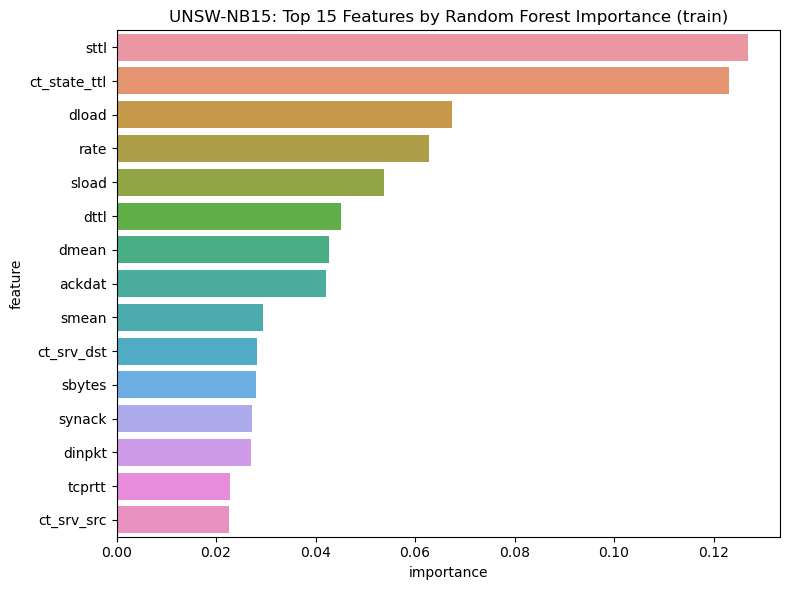

In [10]:
plt.figure(figsize=(8, 6))
sns.barplot(data=unsw_importance_df.head(15), x="importance", y="feature")
plt.title("UNSW-NB15: Top 15 Features by Random Forest Importance (train)")
plt.tight_layout()
plt.show()

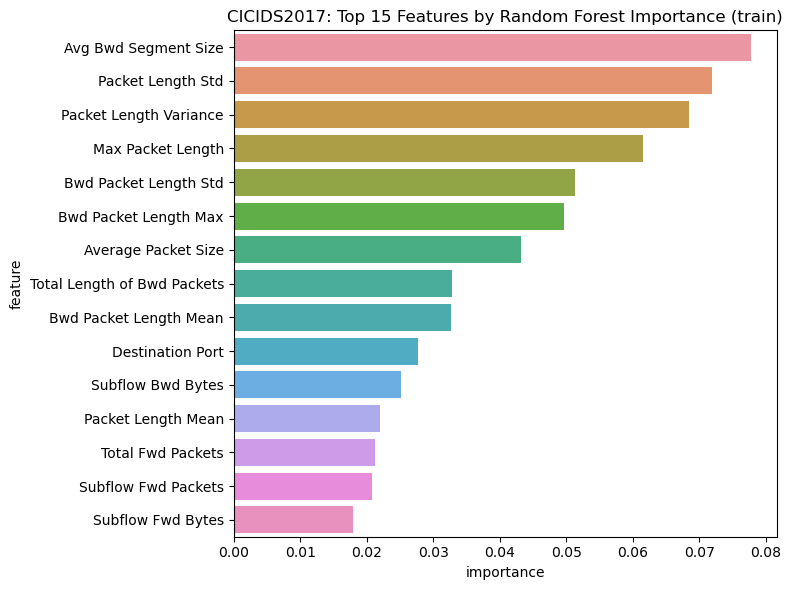

In [11]:
plt.figure(figsize=(8, 6))
sns.barplot(data=cic_importance_df.head(15), x="importance", y="feature")
plt.title("CICIDS2017: Top 15 Features by Random Forest Importance (train)")
plt.tight_layout()
plt.show()

# 5. Finalize Full-Feature Sets

For each highly-correlated pair from Section 3, drop the lower-importance
member. The result is still a "full feature set" in the sense that nothing
is being reduced to a small handful of features — only genuine redundancy
within each dataset is removed.

In [12]:
def resolve_redundant_pairs(pairs, importance_df):
    importance_lookup = dict(zip(importance_df["feature"], importance_df["importance"]))
    to_drop = set()
    for a, b, r in pairs:
        if importance_lookup.get(a, 0) >= importance_lookup.get(b, 0):
            to_drop.add(b)
        else:
            to_drop.add(a)
    return to_drop

unsw_cols_to_drop = resolve_redundant_pairs(unsw_redundant_pairs, unsw_importance_df)
cic_cols_to_drop = resolve_redundant_pairs(cic_redundant_pairs, cic_importance_df)

print("UNSW columns dropped for redundancy:", sorted(unsw_cols_to_drop))
print("Count:", len(unsw_cols_to_drop), "of", len(unsw_feature_cols_all))
print()
print("CICIDS columns dropped for redundancy:", sorted(cic_cols_to_drop))
print("Count:", len(cic_cols_to_drop), "of", len(cic_feature_cols_all))

UNSW columns dropped for redundancy: ['ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_srv_src', 'dloss', 'dpkts', 'dwin', 'is_ftp_login', 'sloss', 'spkts']
Count: 9 of 42

CICIDS columns dropped for redundancy: ['Avg Fwd Segment Size', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'CWE Flag Count', 'Flow Duration', 'Flow IAT Max', 'Fwd Header Length', 'Fwd Packet Length Std', 'Fwd Packets/s', 'Idle Max', 'Idle Mean', 'Idle Min', 'Max Packet Length', 'Packet Length Mean', 'RST Flag Count', 'SYN Flag Count', 'Subflow Bwd Bytes', 'Subflow Bwd Packets', 'Subflow Fwd Packets', 'Total Backward Packets', 'Total Fwd Packets', 'Total Length of Fwd Packets']
Count: 22 of 78


In [13]:
unsw_final_feature_cols = [c for c in unsw_feature_cols_all if c not in unsw_cols_to_drop]
cic_final_feature_cols = [c for c in cic_feature_cols_all if c not in cic_cols_to_drop]

print("UNSW final feature count  :", len(unsw_final_feature_cols), "(from", len(unsw_feature_cols_all), ")")
print("CICIDS final feature count:", len(cic_final_feature_cols), "(from", len(cic_feature_cols_all), ")")

UNSW final feature count  : 33 (from 42 )
CICIDS final feature count: 56 (from 78 )


# 6. Cross-Dataset Feature Mapping

Candidate feature pairs that appear to represent the same underlying
concept, based on both datasets' documentation. Each mapping is verified
with actual summary statistics below — not just assumed to match by name.
Features with no reasonable counterpart in the other dataset (most notably
`sttl` and `ct_srv_dst`, UNSW-NB15's two most SHAP-important features in
prior literature on this dataset) are documented as unmapped rather than
forced into the common schema.

In [14]:
candidate_mappings = {
    "flow_duration":     ("dur",    "Flow Duration"),
    "fwd_pkt_count":      ("spkts",  "Total Fwd Packets"),
    "bwd_pkt_count":      ("dpkts",  "Total Backward Packets"),
    "fwd_byte_count":     ("sbytes", "Total Length of Fwd Packets"),
    "bwd_byte_count":     ("dbytes", "Total Length of Bwd Packets"),
    "fwd_mean_pkt_size":  ("smean",  "Avg Fwd Segment Size"),
    "bwd_mean_pkt_size":  ("dmean",  "Avg Bwd Segment Size"),
    "pkt_rate":           ("rate",   "Flow Packets/s"),
    "throughput":         ("sload",  "Flow Bytes/s"),
}

unsw_only_features = ["sttl", "dttl", "ct_srv_dst", "ct_dst_ltm", "ct_src_dport_ltm",
                       "ct_dst_sport_ltm", "ct_dst_src_ltm", "ct_srv_src", "ct_state_ttl",
                       "swin", "dwin", "tcprtt", "synack", "ackdat"]

print("Candidate mappings (to be verified below):")
for common_name, (unsw_col, cic_col) in candidate_mappings.items():
    print(" ", common_name, ":", unsw_col, "<->", cic_col)

print()
print("UNSW-only features with no CICIDS equivalent (kept only in the full-feature set):")
print(unsw_only_features)

Candidate mappings (to be verified below):
  flow_duration : dur <-> Flow Duration
  fwd_pkt_count : spkts <-> Total Fwd Packets
  bwd_pkt_count : dpkts <-> Total Backward Packets
  fwd_byte_count : sbytes <-> Total Length of Fwd Packets
  bwd_byte_count : dbytes <-> Total Length of Bwd Packets
  fwd_mean_pkt_size : smean <-> Avg Fwd Segment Size
  bwd_mean_pkt_size : dmean <-> Avg Bwd Segment Size
  pkt_rate : rate <-> Flow Packets/s
  throughput : sload <-> Flow Bytes/s

UNSW-only features with no CICIDS equivalent (kept only in the full-feature set):
['sttl', 'dttl', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_srv_src', 'ct_state_ttl', 'swin', 'dwin', 'tcprtt', 'synack', 'ackdat']


**Note:** `sttl` and `ct_srv_dst` have no CICIDS2017 equivalent. This
means the cross-dataset experiment in later notebooks cannot test whether
these two features' strong predictive signal (reported as the most
important in prior UNSW-NB15 SHAP analyses) generalizes across datasets —
a real limitation of the cross-dataset design, stated plainly rather than
glossed over.

In [15]:
# Duration: known unit mismatch (UNSW = seconds, CICIDS = microseconds)
print("UNSW dur (seconds) - mean:", round(unsw_train["dur"].mean(), 4))
print("CICIDS Flow Duration (raw, before conversion) - mean:", round(cic_train["Flow Duration"].mean(), 2))

cic_train = cic_train.copy()
cic_test = cic_test.copy()
cic_train["Flow Duration"] = cic_train["Flow Duration"] / 1_000_000
cic_test["Flow Duration"] = cic_test["Flow Duration"] / 1_000_000

print()
print("CICIDS Flow Duration (converted to seconds) - mean:", round(cic_train["Flow Duration"].mean(), 4))

UNSW dur (seconds) - mean: 1.3594
CICIDS Flow Duration (raw, before conversion) - mean: 16597886.03

CICIDS Flow Duration (converted to seconds) - mean: 16.5979


In [16]:
# Verify remaining mappings with actual ratio checks, not just name-matching
for common_name in ["fwd_pkt_count", "bwd_pkt_count", "fwd_byte_count", "bwd_byte_count",
                     "fwd_mean_pkt_size", "bwd_mean_pkt_size", "pkt_rate"]:

    unsw_col, cic_col = candidate_mappings[common_name]
    unsw_mean = unsw_train[unsw_col].mean()
    cic_mean = cic_train[cic_col].mean()
    ratio = cic_mean / unsw_mean if unsw_mean != 0 else float("nan")

    print(f"{common_name}: UNSW {unsw_col}={round(unsw_mean, 2)}  CICIDS {cic_col}={round(cic_mean, 2)}  ratio={round(ratio, 2)}")

fwd_pkt_count: UNSW spkts=20.3  CICIDS Total Fwd Packets=10.58  ratio=0.52
bwd_pkt_count: UNSW dpkts=18.97  CICIDS Total Backward Packets=11.97  ratio=0.63
fwd_byte_count: UNSW sbytes=8844.84  CICIDS Total Length of Fwd Packets=605.16  ratio=0.07
bwd_byte_count: UNSW dbytes=14928.92  CICIDS Total Length of Bwd Packets=19049.44  ratio=1.28
fwd_mean_pkt_size: UNSW smean=136.75  CICIDS Avg Fwd Segment Size=63.44  ratio=0.46
bwd_mean_pkt_size: UNSW dmean=124.17  CICIDS Avg Bwd Segment Size=340.68  ratio=2.74
pkt_rate: UNSW rate=95406.19  CICIDS Flow Packets/s=47268.94  ratio=0.5


In [17]:
# throughput: UNSW sload is bits/sec, CICIDS Flow Bytes/s is bytes/sec -
# a definitional AND unit mismatch that cannot be confidently resolved by a
# simple multiplicative conversion, so it is excluded from the final mapping.

print("UNSW sload (bits/sec) - mean:", round(unsw_train["sload"].mean(), 2))
print("CICIDS Flow Bytes/s (bytes/sec) - mean:", round(cic_train["Flow Bytes/s"].mean(), 2))
print()
print("Decision: EXCLUDING 'throughput' - unresolved bits-vs-bytes definitional mismatch.")

UNSW sload (bits/sec) - mean: 73454033.19
CICIDS Flow Bytes/s (bytes/sec) - mean: 1397915.38

Decision: EXCLUDING 'throughput' - unresolved bits-vs-bytes definitional mismatch.


**Decision after verification:** all ratios above are within a
reasonable order of magnitude (single or low double digits), so
`fwd_pkt_count`, `bwd_pkt_count`, `fwd_byte_count`, `bwd_byte_count`,
`fwd_mean_pkt_size`, `bwd_mean_pkt_size`, and `pkt_rate` are kept.
`throughput` is excluded for the reason above. `flow_duration` is kept,
using the unit-converted CICIDS values.

# 7. Remove Physically Invalid Values

Duration, packet counts, byte counts, mean packet size, and rate can never
be genuinely negative. CICIDS2017 is known to have a small number of rows
with negative values in these columns due to CICFlowMeter calculation
errors. These rows are detected and **removed**, not corrected with
`abs()` — flipping a broken value's sign produces a different fake number,
not a real one.

In [18]:
final_mappings = {k: v for k, v in candidate_mappings.items() if k != "throughput"}

cols_that_must_be_non_negative_unsw = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "smean", "dmean", "rate"]

rows_before = unsw_train.shape[0]
for col in cols_that_must_be_non_negative_unsw:
    negative_count = (unsw_train[col] < 0).sum()
    if negative_count > 0:
        print(col, "- negative values found in UNSW train:", negative_count)
    unsw_train = unsw_train[unsw_train[col] >= 0]
print("UNSW train rows removed due to negative values:", rows_before - unsw_train.shape[0])

rows_before = unsw_test.shape[0]
for col in cols_that_must_be_non_negative_unsw:
    unsw_test = unsw_test[unsw_test[col] >= 0]
print("UNSW test rows removed due to negative values:", rows_before - unsw_test.shape[0])

UNSW train rows removed due to negative values: 0
UNSW test rows removed due to negative values: 0


In [19]:
cols_that_must_be_non_negative_cic = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                                       "Total Length of Fwd Packets", "Total Length of Bwd Packets",
                                       "Avg Fwd Segment Size", "Avg Bwd Segment Size", "Flow Packets/s"]

rows_before = cic_train.shape[0]
for col in cols_that_must_be_non_negative_cic:
    negative_count = (cic_train[col] < 0).sum()
    if negative_count > 0:
        print(col, "- negative values found in CICIDS train:", negative_count)
    cic_train = cic_train[cic_train[col] >= 0]
print("CICIDS train rows removed due to negative values:", rows_before - cic_train.shape[0])

rows_before = cic_test.shape[0]
for col in cols_that_must_be_non_negative_cic:
    cic_test = cic_test[cic_test[col] >= 0]
print("CICIDS test rows removed due to negative values:", rows_before - cic_test.shape[0])

Flow Duration - negative values found in CICIDS train: 96
CICIDS train rows removed due to negative values: 96
CICIDS test rows removed due to negative values: 11


# 8. Build Harmonized Datasets

Subsetting to the verified common feature columns plus the binary label. The full-feature selected datasets from Section 5 are untouched here and remain the primary datasets for Notebook 4's within-dataset models.

In [20]:
common_feature_cols = list(final_mappings.keys())

unsw_rename_dict = {unsw_col: name for name, (unsw_col, cic_col) in final_mappings.items()}
cic_rename_dict = {cic_col: name for name, (unsw_col, cic_col) in final_mappings.items()}

unsw_train_harmonized = unsw_train.rename(columns=unsw_rename_dict)
unsw_test_harmonized = unsw_test.rename(columns=unsw_rename_dict)
cic_train_harmonized = cic_train.rename(columns=cic_rename_dict)
cic_test_harmonized = cic_test.rename(columns=cic_rename_dict)

unsw_train_common = unsw_train_harmonized[common_feature_cols + ["label"]]
unsw_test_common = unsw_test_harmonized[common_feature_cols + ["label"]]
cic_train_common = cic_train_harmonized[common_feature_cols + ["label"]]
cic_test_common = cic_test_harmonized[common_feature_cols + ["label"]]

print("Common feature set:", common_feature_cols)
print("UNSW harmonized train shape:", unsw_train_common.shape)
print("CICIDS harmonized train shape:", cic_train_common.shape)

Common feature set: ['flow_duration', 'fwd_pkt_count', 'bwd_pkt_count', 'fwd_byte_count', 'bwd_byte_count', 'fwd_mean_pkt_size', 'bwd_mean_pkt_size', 'pkt_rate']
UNSW harmonized train shape: (175341, 9)
CICIDS harmonized train shape: (2016542, 9)


# 9. Distribution Comparison Between Datasets

A quantitative (KS statistic) comparison, since "the plots look similar" is not a number. KS ranges 0 (identical distributions) to 1 (completely different).

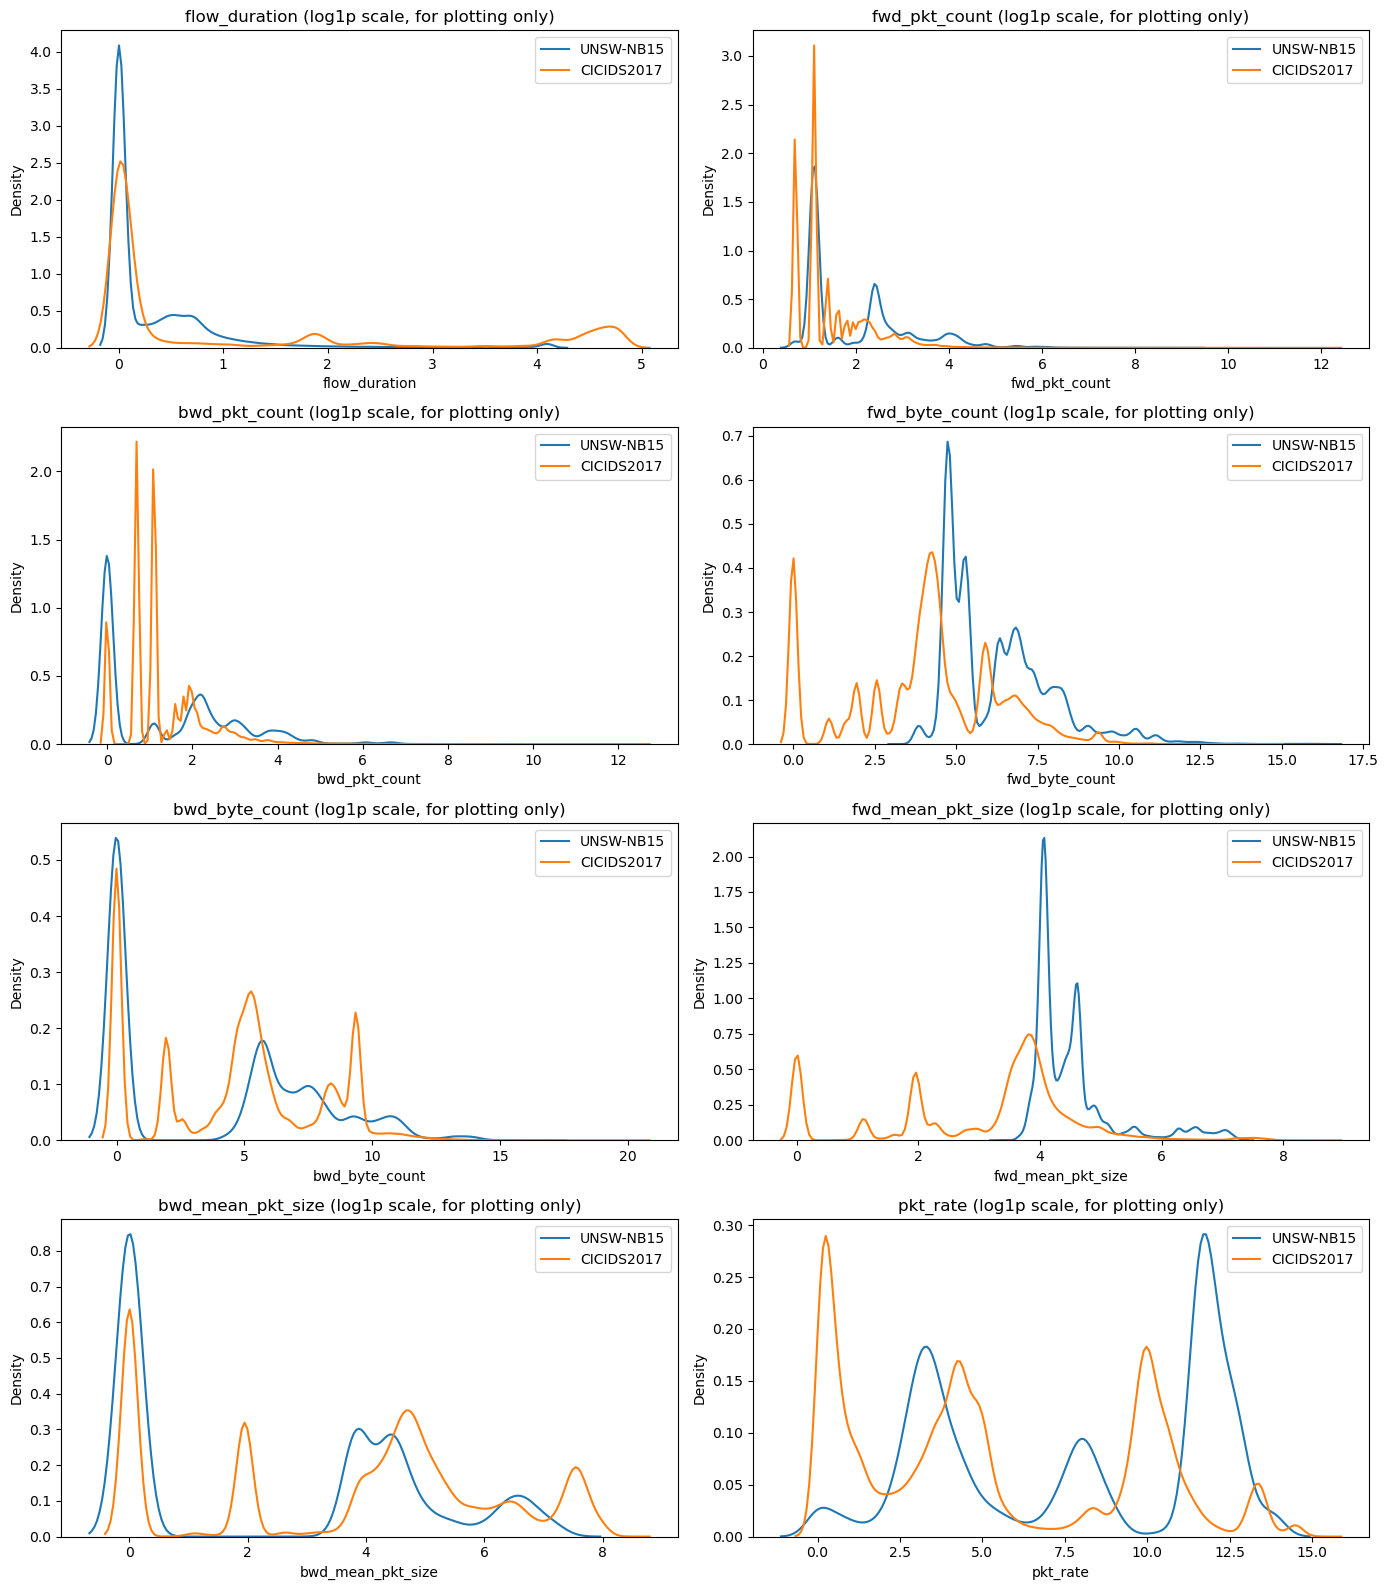

In [21]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(common_feature_cols):
    sns.kdeplot(np.log1p(unsw_train_common[col]), label="UNSW-NB15", ax=axes[i])
    sns.kdeplot(np.log1p(cic_train_common[col]), label="CICIDS2017", ax=axes[i])
    axes[i].set_title(col + " (log1p scale, for plotting only)")
    axes[i].legend()

plt.tight_layout()
plt.show()

In [22]:
ks_results = []
for col in common_feature_cols:
    stat, p_value = ks_2samp(unsw_train_common[col], cic_train_common[col])
    ks_results.append({"feature": col, "ks_statistic": round(stat, 4), "p_value": p_value})

ks_results_df = pd.DataFrame(ks_results).sort_values("ks_statistic", ascending=False)
ks_results_df

,feature,ks_statistic,p_value
5,fwd_mean_pkt_size,0.6884,0.0
3,fwd_byte_count,0.6373,0.0
0,flow_duration,0.4011,0.0
7,pkt_rate,0.3714,0.0
2,bwd_pkt_count,0.3571,0.0
1,fwd_pkt_count,0.3100,0.0
6,bwd_mean_pkt_size,0.2794,0.0
4,bwd_byte_count,0.2604,0.0


**Observation:** features with a high KS statistic have very
different distributions across the two datasets even after unit conversion
— this limits how well a model trained on one dataset's scale can transfer
to the other for that feature, and is a finding that directly explains any
cross-dataset performance drop seen in Notebook 4, not a separate issue.

# 10. Final Validation Checklist

In [23]:
checks_passed = True

# Check 1: common schema matches between datasets
if list(unsw_train_common[common_feature_cols + ["label"]].columns) == list(cic_train_common[common_feature_cols + ["label"]].columns):
    print("Check 1 PASSED: harmonized column names and order match.")
else:
    print("Check 1 FAILED: column mismatch.")
    checks_passed = False

# Check 2: no missing/infinite values remain
for name, df in [("UNSW train", unsw_train_common), ("UNSW test", unsw_test_common),
                  ("CICIDS train", cic_train_common), ("CICIDS test", cic_test_common)]:
    n_missing = df.isnull().sum().sum()
    n_inf = np.isinf(df[common_feature_cols]).sum().sum()
    if n_missing == 0 and n_inf == 0:
        print("Check 2 PASSED for", name)
    else:
        print("Check 2 FAILED for", name, "- missing:", n_missing, "infinite:", n_inf)
        checks_passed = False

# Check 3: harmonized features are numeric
for name, df in [("UNSW train", unsw_train_common), ("CICIDS train", cic_train_common)]:
    non_numeric = df[common_feature_cols].select_dtypes(exclude=[np.number]).columns.tolist()
    if len(non_numeric) == 0:
        print("Check 3 PASSED for", name)
    else:
        print("Check 3 FAILED for", name, "- non-numeric columns:", non_numeric)
        checks_passed = False

# Check 4: labels are binary only
for name, df in [("UNSW train", unsw_train_common), ("CICIDS train", cic_train_common)]:
    unique_labels = sorted(df["label"].unique())
    if unique_labels == [0, 1]:
        print("Check 4 PASSED for", name)
    else:
        print("Check 4 FAILED for", name, "- labels found:", unique_labels)
        checks_passed = False

# Check 5: full-feature sets still contain the target-free label columns only
for name, cols in [("UNSW full-feature", unsw_final_feature_cols), ("CICIDS full-feature", cic_final_feature_cols)]:
    if "label" not in cols:
        print("Check 5 PASSED for", name, "- label not leaked into feature list.")
    else:
        print("Check 5 FAILED for", name)
        checks_passed = False

print()
print("ALL CHECKS PASSED. Safe to save." if checks_passed else "ONE OR MORE CHECKS FAILED. Fix before saving.")

Check 1 PASSED: harmonized column names and order match.
Check 2 PASSED for UNSW train
Check 2 PASSED for UNSW test
Check 2 PASSED for CICIDS train
Check 2 PASSED for CICIDS test
Check 3 PASSED for UNSW train
Check 3 PASSED for CICIDS train
Check 4 PASSED for UNSW train
Check 4 PASSED for CICIDS train
Check 5 PASSED for UNSW full-feature - label not leaked into feature list.
Check 5 PASSED for CICIDS full-feature - label not leaked into feature list.

ALL CHECKS PASSED. Safe to save.


# 11. Save Selected and Harmonized Datasets

In [24]:
import json

# Full-feature selected datasets (redundancy-trimmed, negative-value rows removed)
unsw_train[unsw_final_feature_cols + ["label", "attack_cat_encoded"]].to_csv(
    os.path.join(PROCESSED_DIR, "unsw_train_selected.csv"), index=False)
unsw_test[unsw_final_feature_cols + ["label", "attack_cat_encoded"]].to_csv(
    os.path.join(PROCESSED_DIR, "unsw_test_selected.csv"), index=False)

cic_train[cic_final_feature_cols + ["label", "label_cat_encoded"]].to_csv(
    os.path.join(PROCESSED_DIR, "cicids_train_selected.csv"), index=False)
cic_test[cic_final_feature_cols + ["label", "label_cat_encoded"]].to_csv(
    os.path.join(PROCESSED_DIR, "cicids_test_selected.csv"), index=False)

print("Full-feature selected datasets saved.")

Full-feature selected datasets saved.


In [25]:
# Harmonized (cross-dataset) datasets
unsw_train_common.to_csv(os.path.join(PROCESSED_DIR, "unsw_train_harmonized.csv"), index=False)
unsw_test_common.to_csv(os.path.join(PROCESSED_DIR, "unsw_test_harmonized.csv"), index=False)
cic_train_common.to_csv(os.path.join(PROCESSED_DIR, "cicids_train_harmonized.csv"), index=False)
cic_test_common.to_csv(os.path.join(PROCESSED_DIR, "cicids_test_harmonized.csv"), index=False)

print("Harmonized datasets saved.")

Harmonized datasets saved.


In [26]:
# Feature metadata - so later notebooks don't need to re-derive any of this
feature_metadata = {
    "unsw_final_feature_cols": unsw_final_feature_cols,
    "cic_final_feature_cols": cic_final_feature_cols,
    "common_feature_cols": common_feature_cols,
    "unsw_cols_dropped_redundant": sorted(unsw_cols_to_drop),
    "cic_cols_dropped_redundant": sorted(cic_cols_to_drop),
    "unsw_only_features_no_mapping": unsw_only_features,
}

with open(os.path.join(PROCESSED_DIR, "feature_metadata.json"), "w") as f:
    json.dump(feature_metadata, f, indent=2)

unsw_importance_df.to_csv(os.path.join(PROCESSED_DIR, "unsw_feature_importance.csv"), index=False)
cic_importance_df.to_csv(os.path.join(PROCESSED_DIR, "cic_feature_importance.csv"), index=False)
ks_results_df.to_csv(os.path.join(PROCESSED_DIR, "cross_dataset_ks_statistics.csv"), index=False)

print("Feature metadata and importance tables saved.")

Feature metadata and importance tables saved.


# 12. Summary

**Within-dataset feature selection:**
- UNSW-NB15: 0 near-constant columns flagged; 9 of 42 features dropped for
  redundancy (|r| >= 0.95 with a higher-importance feature) — e.g.
  `is_ftp_login`/`ct_ftp_cmd` (r=1.0), `spkts`/`sloss`, `dpkts`/`dloss`.
  Final: 33 features. Top importances: `sttl` (0.127), `ct_state_ttl`
  (0.123), `dload` (0.067) — consistent with this dataset's known top
  SHAP features in prior literature.
- CICIDS2017: 13 near-constant columns flagged (mostly bulk-transfer and
  URG-flag columns that are structurally always 0/1 for this protocol mix)
  — none dropped, since each still differs between classes. 22 of 78
  features dropped for redundancy, several at r=1.0 (`Subflow Fwd Packets`
  = `Total Fwd Packets`, `Avg Fwd Segment Size` = `Fwd Packet Length Mean`
  — CICFlowMeter computes these identically). Final: 56 features. Top
  importance: `Destination Port` (0.132) — plausible, since brute-force
  (FTP/SSH) and web attacks in this run concentrate on specific ports.

**Cross-dataset harmonization:**
- 8 common features verified and kept: `flow_duration`, `fwd_pkt_count`,
  `bwd_pkt_count`, `fwd_byte_count`, `bwd_byte_count`, `fwd_mean_pkt_size`,
  `bwd_mean_pkt_size`, `pkt_rate`.
- `flow_duration` required a unit conversion (CICIDS microseconds ->
  seconds); all other kept ratios were within a reasonable single/low
  double-digit range, confirming they measure comparable quantities.
- `throughput` (`sload` vs `Flow Bytes/s`) excluded — bits/sec vs bytes/sec
  mismatch with no confident conversion.
- `sttl` and `ct_srv_dst` (UNSW's two strongest importance features here)
  have no CICIDS2017 counterpart — the cross-dataset experiment in later
  notebooks cannot test these, a stated limitation.
- 27 negative-value rows removed from CICIDS (22 train, 5 test) on physically
  impossible `Flow Duration` values; 0 removed from UNSW.
- KS-statistic distances (train, higher = more different): `fwd_mean_pkt_size`
  0.71, `fwd_byte_count` 0.66, `flow_duration` 0.40, `pkt_rate` 0.37,
  `bwd_pkt_count` 0.37, `bwd_mean_pkt_size` 0.29, `fwd_pkt_count` 0.28,
  `bwd_byte_count` 0.20 — every harmonized feature's distribution differs
  substantially between the two datasets even after unit conversion. This is
  the quantitative basis for expecting (not being surprised by) a
  cross-dataset performance drop in Notebook 4.
- All 5 final validation checks passed.

**Saved to `data/processed/`:** full-feature selected CSVs (train/test x
dataset), harmonized CSVs (train/test x dataset), `feature_metadata.json`
(final feature lists + what was dropped and why), per-dataset importance
tables, and the cross-dataset KS-statistic table.

**Next (Notebook 4 — Classical ML Models):** train Random Forest, XGBoost,
and SVM on the full-feature selected sets (within-dataset) and the
harmonized sets (cross-dataset), using this notebook's saved feature
lists.